# Operaciones de aprendizaje automático
## Maestría en Inteligencia Artificial Aplicada

### TC5061 | Proyecto MiBici: propuesta y base reproducible | Colaborativo

#### **Equipo:** 7
#### **Nombre:** Daniel Sánchez Hernández
#### **Matrícula:** A01840324

## Objetivo
Análisis exploratorio de datos (EDA) de los viajes de MiBici orientado a la **P1 (regresión)**: ¿cuántos viajes se iniciarán en una estación o zona en un periodo futuro?

El EDA busca evidencia para definir, con criterio propio, la unidad de predicción (estación o zona), el periodo (hora, día u otro) y las decisiones de limpieza de datos que afectan a esa pregunta.

## Datos de entrada
- **Viajes:** `data/interim/viajes_2020-01_2026-09.parquet`, generado por la ingesta del proyecto (`dataset.py`, etapa `construir`): 81 meses y 27086557 registros unidos y normalizados, todavía sin limpiar, para poder cuantificar aquí los problemas de calidad.
- **Viajes limpios:** `data/processed/viajes_limpios_2020-01_2026-09.parquet` (27026645 registros), generado por la etapa `limpiar` de la misma ingesta. Se usa para medir la demanda con los mismos viajes con los que se construirá el target.
- **Estaciones:** la nomenclatura más reciente en `data/raw/estaciones/`.

Antes de ejecutar este notebook se debe ejecutar la ingesta desde la raíz del repositorio con `make data` (o `python -m tc5061_proyecto_equipo07.dataset todo`).

In [1]:
# Importación de librerías y registro de versiones (evidencia de reproducibilidad)
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from tc5061_proyecto_equipo07 import config as cfg

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)

2026-10-16 12:55:13.039 | INFO     | tc5061_proyecto_equipo07.config:<module>:14 - PROJ_ROOT path is: /home/daniel/mlops_lab/MLOps-ProyectoMiBici-Equipo7


Python      : 3.11.17
pandas      : 3.0.5
numpy       : 1.26.4
matplotlib  : 3.11.2
seaborn     : 0.13.2


## Configuración global

Las rutas, la random seed y los colores se toman de `config.py` del módulo, para que la configuración viva en un solo lugar:
- **Rutas:** Parquet de viajes y carpeta de la nomenclatura de estaciones.
- **Random seed:** para que cualquier muestreo sea reproducible.
- **Opciones de visualización** de pandas (propias de este notebook).
- **Colores:** paleta Okabe-Ito, apta para daltonismo, referida por nombre.

In [2]:
# Rutas y random seed centralizadas en config.py
RUTA_PARQUET_VIAJES = cfg.RUTA_VIAJES_INTERIM
RUTA_VIAJES_LIMPIOS = cfg.RUTA_VIAJES_LIMPIOS
RUTA_ESTACIONES_CRUDAS = cfg.RUTA_ESTACIONES_CRUDAS
SEMILLA = cfg.SEMILLA

# Rango del análisis y horas en que el servicio no opera
MES_INICIO = cfg.MES_INICIO
MES_FIN = cfg.MES_FIN
HORAS_SIN_SERVICIO = cfg.HORAS_SIN_SERVICIO

# Opciones de visualización de pandas
pd.set_option("display.max_columns", None)   # mostrar todas las columnas
pd.set_option("display.max_rows", 120)       # suficiente para tablas mensuales
pd.set_option("display.width", 200)          # ancho suficiente para tablas amplias

# Paleta Okabe-Ito (apta para daltonismo), definida en config.py
AZUL = cfg.AZUL
NARANJA = cfg.NARANJA
AMARILLO = cfg.AMARILLO
VERDE = cfg.VERDE
GRIS = cfg.GRIS

## Carga de los datos

El Parquet conserva los tipos definidos en la lectura (enteros que aceptan nulos, fechas y categorías), por lo que no hace falta volver a convertirlos. Los nombres de las columnas ya vienen normalizados en minúsculas y sin acentos (por ejemplo, `anio_de_nacimiento`). De la nomenclatura se toma el archivo más reciente.

In [3]:
# Carga de viajes (Parquet) y de la nomenclatura más reciente
viajes = pd.read_parquet(RUTA_PARQUET_VIAJES)
ruta_nomenclatura = sorted(RUTA_ESTACIONES_CRUDAS.glob("nomenclatura_*.csv"))[-1]
estaciones = pd.read_csv(ruta_nomenclatura)

print("Viajes     :", viajes.shape)
print(f"Memoria    : {viajes.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print("Estaciones :", estaciones.shape, "|", ruta_nomenclatura.name)
print("-" * 45)
print(viajes.dtypes.to_string())
print("-" * 45)
print(estaciones.dtypes.to_string())

Viajes     : (27086557, 9)
Memoria    : 1265.8 MB
Estaciones : (484, 5) | nomenclatura_2026_09.csv
---------------------------------------------
viaje_id                       Int64
usuario_id                     Int64
genero                      category
anio_de_nacimiento             Int16
inicio_del_viaje      datetime64[us]
fin_del_viaje         datetime64[us]
origen_id                      Int32
destino_id                     Int32
periodo_archivo             category
---------------------------------------------
id              int64
name              str
latitude      float64
longitude     float64
dpcapacity      int64


## Paso 2: Análisis exploratorio de datos (EDA)

### 2.1 Calidad de los datos

Antes de analizar distribuciones y patrones se revisan los problemas que pueden distorsionar el conteo de viajes, que es la base de la P1:
- **Duplicados:** filas idénticas e identificadores de viaje repetidos.
- **Duración de los viajes:** viajes con duración negativa, cero o extremadamente larga.
- **Estaciones:** estaciones de los viajes que no están en la nomenclatura, y al revés.

En esta sección solo se cuantifican los problemas; las decisiones se toman en la limpieza de datos.

In [4]:
# Duplicados: filas idénticas en todas las columnas e identificadores de viaje repetidos
filas_duplicadas = viajes.duplicated()
ids_repetidos = viajes["viaje_id"].duplicated()

print("Filas idénticas a una anterior :", filas_duplicadas.sum())
print("viaje_id repetidos             :", ids_repetidos.sum())
print("viaje_id repetidos sin ser fila idéntica:", (ids_repetidos & ~filas_duplicadas).sum())
print("-" * 45)

# En qué meses aparecen las filas duplicadas
duplicados_por_mes = viajes.loc[filas_duplicadas, "periodo_archivo"].value_counts()
print(duplicados_por_mes[duplicados_por_mes > 0].sort_index().to_string())

Filas idénticas a una anterior : 758
viaje_id repetidos             : 758
viaje_id repetidos sin ser fila idéntica: 0
---------------------------------------------
periodo_archivo
2026-09    758


In [5]:
# Duración de cada viaje en minutos
duracion_min = (viajes["fin_del_viaje"] - viajes["inicio_del_viaje"]).dt.total_seconds().div(60).astype("float32")

print("Duración negativa      :", (duracion_min < 0).sum())
print("Duración cero          :", (duracion_min == 0).sum())
print("Duración > 24 horas    :", (duracion_min > 24 * 60).sum())
print("-" * 45)

# Percentiles para ver la forma de la distribución sin que los extremos la oculten
percentiles = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
duracion_min.describe(percentiles=percentiles).round(2).to_frame("duracion_min").T

Duración negativa      : 0
Duración cero          : 55035
Duración > 24 horas    : 159
---------------------------------------------


,count,mean,std,min,0.1%,1%,5%,25%,50%,75%,95%,99%,99.9%,max
duracion_min,27086557.0,11.0,15.48,0.0,0.0,0.2,2.02,5.7,9.45,14.75,24.15,32.8,58.72,28150.77


In [6]:
# Estaciones de los viajes contra estaciones de la nomenclatura
ids_nomenclatura = set(estaciones["id"])
ids_origen = set(viajes["origen_id"].unique().tolist())
ids_destino = set(viajes["destino_id"].unique().tolist())

sin_nomenclatura = sorted((ids_origen | ids_destino) - ids_nomenclatura)
sin_viajes = sorted(ids_nomenclatura - (ids_origen | ids_destino))
viajes_afectados = (viajes["origen_id"].isin(sin_nomenclatura) | viajes["destino_id"].isin(sin_nomenclatura)).sum()

print("Estaciones en viajes sin nomenclatura:", len(sin_nomenclatura), sin_nomenclatura)
print("Viajes que usan esas estaciones      :", viajes_afectados)
print("Estaciones en nomenclatura sin viajes:", len(sin_viajes))

Estaciones en viajes sin nomenclatura: 3 [124, 405, 407]
Viajes que usan esas estaciones      : 3961
Estaciones en nomenclatura sin viajes: 12


**Observaciones de la calidad de los datos:**
- **Duplicados:** 758 filas son idénticas a otra en todas sus columnas, y son exactamente los 758 `viaje_id` repetidos; ningún identificador se repite con contenido distinto. Son copias exactas y todas están en el archivo de 2026-09, lo que apunta a un error de publicación de ese mes. Eliminarlas no pierde información.
- **Duración:** no hay duraciones negativas. Hay 55035 viajes de duración cero (0.20%) y el 1% dura 12 segundos o menos (0.20 min), lo que sugiere intentos de retiro que no se concretaron. Para la P1 importan porque inflarían el conteo de viajes iniciados.
- **Viajes muy largos:** 159 viajes duran más de 24 horas, con un máximo de 28150.77 min (unos 19.5 días). La mediana es de 9.45 min y el 99.9% dura 58.72 min o menos. Un viaje largo cuenta una sola vez como inicio, así que afecta el análisis de duración pero no el conteo de la P1.
- **Estaciones:** 3 estaciones de los viajes (124, 405 y 407) no aparecen en la nomenclatura vigente; las usan 3961 viajes (0.01%). Esos viajes se pueden contar por estación, pero no ubicar en el mapa ni asignar a una zona. Además, 12 estaciones de la nomenclatura no tienen viajes en el rango (posiblemente nuevas o inactivas, por verificar).

### 2.2 Estadísticas descriptivas

Los identificadores (`viaje_id`, `usuario_id`, `origen_id`, `destino_id`) son números pero no cantidades: su media no tiene significado, por lo que se describen como categóricas. Las variables numéricas con significado son la duración del viaje, calculada en la sección anterior, y el año de nacimiento.

In [7]:
# Variables numéricas: estadísticas descriptivas con skewness y kurtosis
numericas = pd.DataFrame({"duracion_min": duracion_min,
                          "anio_de_nacimiento": viajes["anio_de_nacimiento"].astype("float32"),
})
estadisticas = numericas.describe().T
estadisticas["skewness"] = numericas.skew()
estadisticas["kurtosis"] = numericas.kurt()
estadisticas.astype("float64").round(2)  # float64 para que el redondeo se muestre exacto

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
duracion_min,27086557.0,11.00,15.48,0.0,5.7,9.45,14.75,28150.77,685.3,989894.31
anio_de_nacimiento,27051936.0,1989.06,16.91,1.0,1984.0,1992.00,1997.00,2023.00,-67.3,7619.17


In [8]:
# Variables categóricas: valores distintos, valor más frecuente y su frecuencia
columnas_categoricas = ["genero", "origen_id", "destino_id", "periodo_archivo"]
viajes[columnas_categoricas].astype("category").describe().T

,count,unique,top,freq
genero,26948912,2,M,19638215
origen_id,27086557,475,51,567876
destino_id,27086557,475,51,716503
periodo_archivo,27086557,81,2026-09,490056


In [9]:
# Género: conteo y porcentaje, incluyendo los nulos
for columna in ["genero"]:
    conteo = pd.concat([viajes[columna].value_counts(dropna=False),
                        viajes[columna].value_counts(dropna=False, normalize=True).mul(100).round(2)],
                       axis=1, keys=["conteo", "porcentaje"],
    )
    print(conteo)
    print("-" * 45)

          conteo  porcentaje
genero                      
M       19638215       72.50
F        7310697       26.99
NaN       137645        0.51
---------------------------------------------


**Observaciones de las estadísticas descriptivas:**
- **Duración:** media de 11.00 min y mediana de 9.45 min. La skewness (685.30) y la kurtosis (989894.31) son extremas: unos pocos viajes de días estiran la cola derecha. La mediana y los percentiles describen mejor el viaje típico que la media.
- **Año de nacimiento:** el 50% central está entre 1984 y 1997 (mediana 1992), pero el rango va de 1 a 2023. La skewness negativa (-67.30) y la kurtosis alta (7619.17) vienen de valores imposibles en el extremo bajo; también hay años recientes poco plausibles. Se cuantifican en la siguiente sección.
- **Género:** 72.50% `M`, 26.99% `F` y 0.51% nulos.
- **Estaciones:** la estación 51 es la más frecuente como origen (567876 viajes, 2.10% del total) y como destino (716503, 2.65%); recibe más viajes de los que salen de ella.
- **Periodos:** 2026-09 es el mes con más registros (490056), consistente con el inventario.

### 2.3 Distribuciones

Para las gráficas se usa una muestra aleatoria de 500000 viajes con la random seed del proyecto: con 27 millones de puntos la KDE tarda mucho y la forma de la distribución no cambia. Las estadísticas de las secciones anteriores sí usan todos los datos.

En la duración, la gráfica se limita al percentil 99.9 (58.72 min) para que la cola extrema no aplaste el resto de la distribución; el recorte es solo visual.

In [10]:
def graficar_distribucion(serie, titulo, etiqueta):
    """Histograma con KDE y boxplot horizontal con la media de una variable numérica."""
    valores = serie.dropna()
    fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                          gridspec_kw={"height_ratios": [3, 1]})
    sns.histplot(valores, stat="density", bins=50, color=AZUL, ax=ax_hist)
    sns.kdeplot(valores, color=AMARILLO, linestyle="--", linewidth=2, ax=ax_hist)
    sns.boxplot(x=valores, orient="h", color=AZUL, showmeans=True, ax=ax_box,
                meanprops={"marker": "s", "markerfacecolor": AMARILLO, "markeredgecolor": AMARILLO, "markersize": 6})
    ax_hist.set_title(titulo)
    ax_box.set_xlabel(etiqueta)
    plt.tight_layout()
    plt.show()

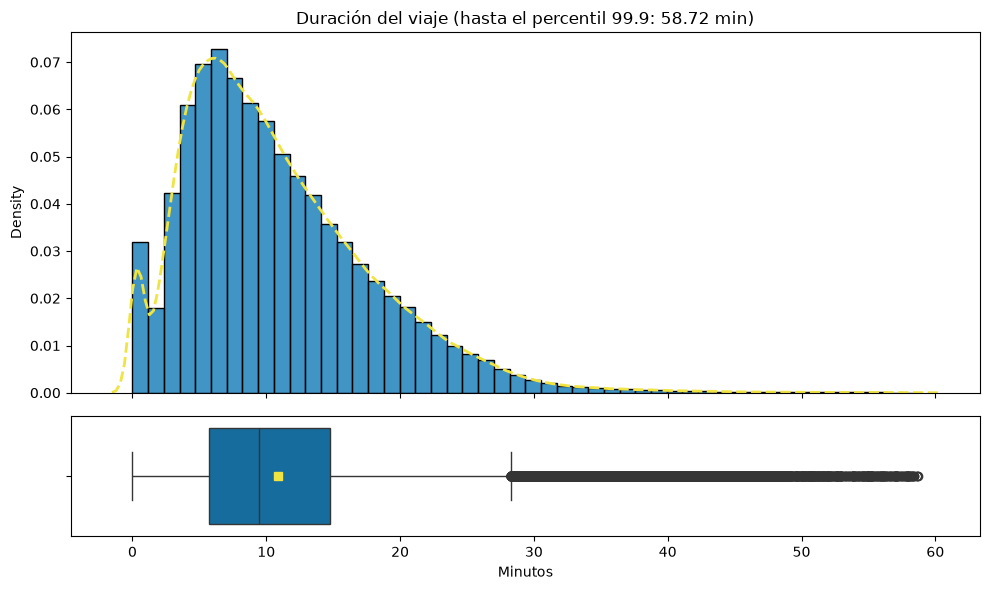

In [11]:
# Muestra reproducible para las gráficas
muestra = numericas.sample(n=500_000, random_state=SEMILLA)

limite_duracion = duracion_min.quantile(0.999)
graficar_distribucion(muestra.loc[muestra["duracion_min"] <= limite_duracion, "duracion_min"],
                      f"Duración del viaje (hasta el percentil 99.9: {limite_duracion:.2f} min)", "Minutos")

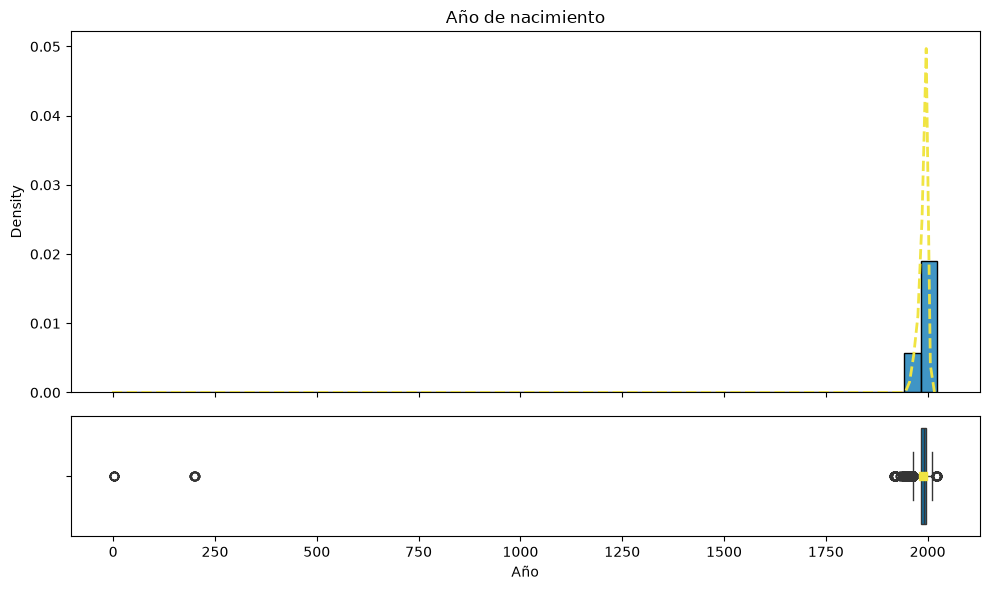

In [12]:
graficar_distribucion(muestra["anio_de_nacimiento"], "Año de nacimiento", "Año")

In [13]:
# Valores extremos del año de nacimiento: los 10 más bajos y los 10 más altos, con su número de viajes
conteo_anios = viajes["anio_de_nacimiento"].value_counts().sort_index()
print("Años más bajos:")
print(conteo_anios.head(10).to_string())
print("-" * 45)
print("Años más altos:")
print(conteo_anios.tail(10).to_string())

Años más bajos:
anio_de_nacimiento
1        747
199      316
200      189
1420       3
1917      43
1918     589
1920    2742
1922     340
1931      26
1933      68
---------------------------------------------
Años más altos:
anio_de_nacimiento
2004    324366
2005    199539
2006    132968
2007     66494
2008     27803
2009      5014
2010       918
2021       571
2022       379
2023      1151


**Observaciones de las distribuciones:**
- **Duración, dos poblaciones:** la mayoría de los viajes forma una curva con moda cerca de 6 a 7 min. Aparte, hay un pico pegado al cero, separado del resto por un valle, consistente con los viajes de duración cero o de segundos de la revisión de calidad (posibles retiros que no se concretaron). Conviene tratarlos como un grupo distinto en la limpieza de datos.
- **Duración, cola derecha:** el boxplot marca como outliers los viajes de más de unos 28 min (1.5 veces el rango intercuartílico sobre el tercer cuartil), pero los viajes de 30 a 60 min son plausibles. Los valores problemáticos son los de horas o días, que quedan fuera de la gráfica por el recorte en el percentil 99.9. La media (cuadro amarillo) queda a la derecha de la mediana por la asimetría.
- **Año de nacimiento, valores imposibles:** 1 (747 viajes), 199 (316), 200 (189) y 1420 (3). Los valores 199 y 200 podrían ser años capturados de forma incompleta (por ejemplo, 199X o 200X), pero no hay forma de recuperarlos.
- **Año de nacimiento, valores poco plausibles:** 1917 a 1922 (3714 viajes, con 2742 solo en 1920), que implicarían usuarios de más de 100 años, y 2021 a 2023 (2101 viajes), que implicarían usuarios de 0 a 5 años. Entre 2010 y 2021 no hay ningún año, lo que separa estos valores de los usuarios jóvenes reales. La concentración en 1920 sugiere un valor capturado por defecto (interpretación).
- **Impacto en la P1:** son viajes reales con un dato de usuario incorrecto. Si se eliminaran, se perderían inicios de viaje del conteo; si el año llegara a usarse, lo adecuado sería tratarlo como nulo y conservar el viaje.

### 2.4 Patrones temporales

La P1 predice viajes iniciados en un periodo futuro, por lo que primero hay que entender cómo cambia la demanda en el tiempo:
- **Tendencia:** viajes por año, por mes y por día de 2020 a 2026.
- **Continuidad:** días sin ningún viaje, que serían huecos en cualquier serie de tiempo.
- **Ciclos:** promedio de viajes por día de la semana y por hora, y la combinación de ambos.

Se usa la fecha y hora de **inicio** del viaje, porque la P1 cuenta viajes iniciados. Los duplicados y los viajes de duración cero aún no se eliminan; representan el 0.2% de los registros y no cambian los patrones.

In [14]:
# Componentes de fecha y hora del inicio de cada viaje, con tipos pequeños para ahorrar memoria
NOMBRES_DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

inicio = viajes["inicio_del_viaje"]
tiempo = pd.DataFrame({"fecha": inicio.dt.normalize(),
                       "hora": inicio.dt.hour.astype("int8"),
                       "dia_semana": inicio.dt.dayofweek.astype("int8"),
})
viajes_por_dia = tiempo["fecha"].value_counts().sort_index()

# Viajes por año y cambio porcentual contra el año anterior
viajes_por_anio = inicio.dt.year.value_counts().sort_index().to_frame("viajes")
viajes_por_anio["cambio_pct"] = viajes_por_anio["viajes"].pct_change().mul(100).round(2)
viajes_por_anio

,viajes,cambio_pct
inicio_del_viaje,,
2020,2866072,NaN
2021,3184410,11.11
2022,4202942,31.98
2023,4293115,2.15
2024,4645921,8.22
2025,4532032,-2.45
2026,3362065,-25.82


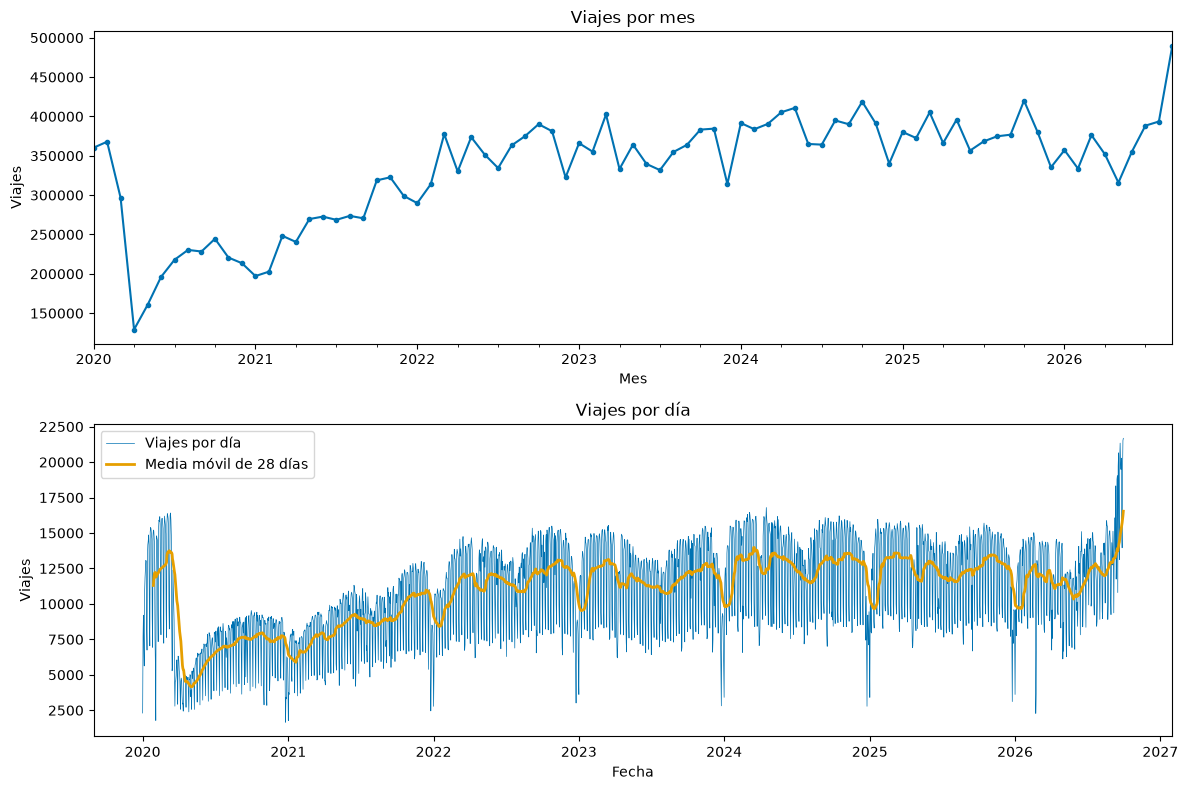

Mes con menos viajes: 2020-04 129276
Mes con más viajes  : 2026-09 490056


In [15]:
# Tendencia: viajes por mes y por día (con media móvil de 28 días)
viajes_por_mes = inicio.dt.to_period("M").value_counts().sort_index()

fig, (ax_mes, ax_dia) = plt.subplots(2, 1, figsize=(12, 8))
viajes_por_mes.plot(ax=ax_mes, color=AZUL, marker="o", markersize=3)
ax_mes.set_title("Viajes por mes")
ax_mes.set_xlabel("Mes")
ax_mes.set_ylabel("Viajes")

ax_dia.plot(viajes_por_dia.index, viajes_por_dia.values, color=AZUL, linewidth=0.5, label="Viajes por día")
ax_dia.plot(viajes_por_dia.rolling(28).mean(), color=NARANJA, linewidth=2, label="Media móvil de 28 días")
ax_dia.set_title("Viajes por día")
ax_dia.set_xlabel("Fecha")
ax_dia.set_ylabel("Viajes")
ax_dia.legend()
plt.tight_layout()
plt.show()

print("Mes con menos viajes:", viajes_por_mes.idxmin(), viajes_por_mes.min())
print("Mes con más viajes  :", viajes_por_mes.idxmax(), viajes_por_mes.max())

In [16]:
# Continuidad: días del rango sin ningún viaje y días con menos viajes
todos_los_dias = pd.date_range(viajes_por_dia.index.min(), viajes_por_dia.index.max(), freq="D")
dias_sin_viajes = todos_los_dias.difference(viajes_por_dia.index)

print("Días en el rango       :", len(todos_los_dias))
print("Días con viajes        :", len(viajes_por_dia))
print("Días sin ningún viaje  :", len(dias_sin_viajes))
print([dia.strftime("%Y-%m-%d") for dia in dias_sin_viajes])
print("-" * 45)
print("Días con menos viajes:")
print(viajes_por_dia.nsmallest(10).to_string())

Días en el rango       : 2465
Días con viajes        : 2465
Días sin ningún viaje  : 0
[]
---------------------------------------------
Días con menos viajes:
fecha
2020-12-25    1652
2021-01-01    1767
2020-02-03    1778
2026-02-22    2275
2020-01-01    2306
2020-04-26    2387
2020-04-12    2438
2021-12-25    2456
2020-05-10    2558
2020-05-03    2567


In [17]:
# Ciclos: promedio de viajes por día de la semana y por hora
# El total de cada combinación se divide entre el número de fechas de ese día de la semana,
# para que las horas sin viajes cuenten como cero en el promedio
fechas_por_dia_semana = pd.Series(viajes_por_dia.index.dayofweek).value_counts().sort_index()
promedio_dia_hora = (tiempo.groupby(["dia_semana", "hora"]).size()
                     .unstack(fill_value=0)
                     .div(fechas_por_dia_semana, axis=0)
)
promedio_dia_hora.index = NOMBRES_DIAS

promedio_por_dia = promedio_dia_hora.sum(axis=1)
print("Promedio de viajes por día de la semana:")
print(promedio_por_dia.round(1).to_string())

Promedio de viajes por día de la semana:
Lunes        11681.1
Martes       12663.4
Miércoles    12580.7
Jueves       12397.1
Viernes      11929.7
Sábado        8507.6
Domingo       7155.1


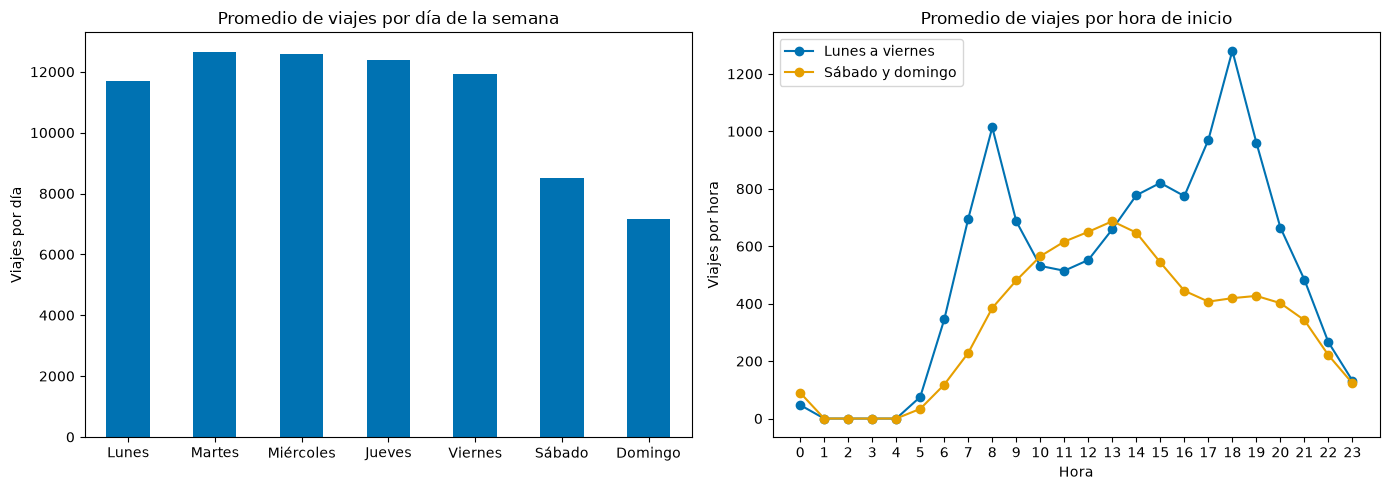

In [18]:
fig, (ax_dias, ax_horas) = plt.subplots(1, 2, figsize=(14, 5))
promedio_por_dia.plot.bar(ax=ax_dias, color=AZUL)
ax_dias.set_title("Promedio de viajes por día de la semana")
ax_dias.set_xlabel("")
ax_dias.set_ylabel("Viajes por día")
ax_dias.tick_params(axis="x", rotation=0)

# Perfil por hora: días laborales contra fin de semana
promedio_dia_hora.iloc[:5].mean().plot(ax=ax_horas, color=AZUL, marker="o", label="Lunes a viernes")
promedio_dia_hora.iloc[5:].mean().plot(ax=ax_horas, color=NARANJA, marker="o", label="Sábado y domingo")
ax_horas.set_title("Promedio de viajes por hora de inicio")
ax_horas.set_xlabel("Hora")
ax_horas.set_ylabel("Viajes por hora")
ax_horas.set_xticks(range(24))
ax_horas.legend()
plt.tight_layout()
plt.show()

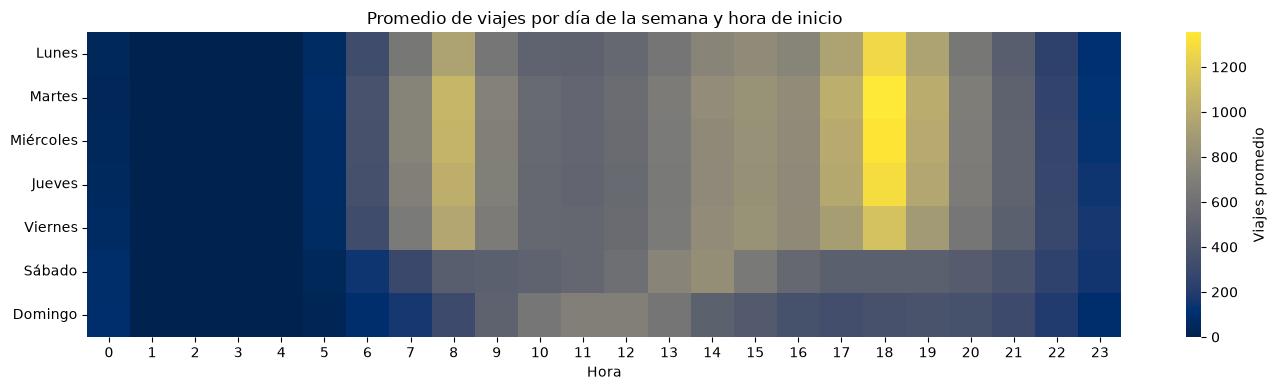

In [19]:
# Heatmap: promedio de viajes por día de la semana y hora
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(promedio_dia_hora, cmap="cividis", ax=ax, cbar_kws={"label": "Viajes promedio"})
ax.set_title("Promedio de viajes por día de la semana y hora de inicio")
ax.set_xlabel("Hora")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Observaciones de los patrones temporales:**
- **Tendencia anual:** 2866072 viajes en 2020. Crecen 11.11% en 2021 y 31.98% en 2022; después el crecimiento se modera (2.15% en 2023 y 8.22% en 2024) y en 2025 baja 2.45%. El -25.82% de 2026 no es una caída: el año solo tiene 9 meses.
- **Cambios de nivel:** el mes con menos viajes es 2020-04 (129276), al inicio de la pandemia de COVID-19, y el de más viajes es 2026-09 (490056). Ese máximo coincide con el mes de los 758 duplicados y con varios días de más de 20000 viajes a finales de septiembre de 2026; es un mes que conviene verificar antes de usarlo para evaluar.
- **Continuidad:** los 2465 días del rango tienen al menos un viaje, así que la serie diaria del sistema no tiene huecos. Esto no garantiza que cada estación tenga viajes todos los días; se revisa al definir la granularidad.
- **Días atípicos:** de los 10 días con menos viajes, 5 son festivos (por ejemplo, 2020-12-25 con 1652 viajes y 2021-01-01 con 1767) y 4 son domingos de abril y mayo de 2020, durante el confinamiento por COVID-19. El 2026-02-22 (domingo, 2275 viajes) no tiene una explicación evidente y queda por verificar.
- **Ciclo semanal:** de lunes a viernes el promedio va de 11681.1 (lunes) a 12663.4 (martes) viajes por día; el sábado baja a 8507.6 y el domingo a 7155.1.
- **Ciclo diario:** de lunes a viernes hay dos picos, cerca de las 8:00 y de las 18:00 (este último el más alto), que corresponden a traslados al trabajo o la escuela. El fin de semana hay un solo pico amplio cerca del mediodía. Entre la 1:00 y las 4:59 casi no hay viajes porque el servicio no opera.
- **Implicaciones para la P1:**
  - La hora y el día de la semana son las variables con más señal, y los perfiles de lunes a viernes y de fin de semana son distintos.
  - La demanda cambia de nivel con el tiempo (pandemia, crecimiento de 2022), por lo que la partición debe ser temporal y un baseline calculado con toda la historia puede quedar sesgado hacia los años de menor demanda.
  - Los días festivos cambian la demanda y conviene marcarlos.
  - Las horas sin servicio pueden excluirse de la unidad de predicción, porque su demanda es prácticamente cero por diseño.

### 2.5 Patrones espaciales

La P1 pregunta por viajes en una **estación o zona**, así que antes de elegir la unidad de predicción hay que ver cómo se reparte la demanda en el espacio:
- **Zonas disponibles:** el nombre de cada estación empieza con un código de municipio (por ejemplo, `(GDL-001)`), que es la agrupación de zonas que ofrecen los datos sin construir nada adicional.
- **Concentración:** qué parte de los viajes se concentra en pocas estaciones.
- **Antigüedad de las estaciones:** cuándo empezó a operar cada estación. Una estación nueva no tiene historia, y eso limita los rezagos que se pueden usar para predecir su demanda.
- **Ubicación:** dónde están las estaciones con más demanda.

Desde aquí se usan los **viajes limpios** (sin duplicados, sin estaciones fuera de la nomenclatura y sin duraciones de cero o de más de 24 horas), porque son los viajes con los que se contará la demanda. Solo se cargan las dos columnas que necesita el análisis.

In [20]:
# Viajes limpios: solo la hora de inicio y la estación de origen, que es lo que cuenta la P1
limpios = pd.read_parquet(RUTA_VIAJES_LIMPIOS, columns=["inicio_del_viaje", "origen_id"])
print("Viajes limpios:", limpios.shape)
print(f"Memoria       : {limpios.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

# Zona de cada estación: código de municipio en el nombre, por ejemplo "(GDL-001) ..." -> GDL
estaciones["zona"] = estaciones["name"].str.extract(r"([A-Z]{3})-\d{3}", expand=False).fillna("SIN_ZONA")

for columna in ["zona"]:
    conteo = pd.concat([estaciones[columna].value_counts(),
                        estaciones[columna].value_counts(normalize=True).mul(100).round(2)],
                       axis=1, keys=["conteo", "porcentaje"],
    )
    print("-" * 45)
    print(conteo)

Viajes limpios: (27026645, 2)
Memoria       : 335.1 MB
---------------------------------------------
      conteo  porcentaje
zona                    
GDL      357       73.76
ZPN      110       22.73
TLQ       17        3.51


In [21]:
# Concentración: viajes que inician en cada estación, de mayor a menor
viajes_por_estacion = limpios["origen_id"].value_counts()
participacion = viajes_por_estacion.div(viajes_por_estacion.sum())

print("Estaciones con viajes de salida:", len(viajes_por_estacion))
for fraccion in [0.1, 0.2, 0.5]:
    n_estaciones = round(len(participacion) * fraccion)
    print(f"El {fraccion:.0%} de las estaciones con más viajes ({n_estaciones}) concentra "
          f"{participacion.iloc[:n_estaciones].sum() * 100:.2f}% de los viajes")
print("-" * 45)

# Las 10 estaciones con más viajes de salida, con su zona
top_estaciones = (viajes_por_estacion.head(10).rename("viajes").to_frame()
                  .join(estaciones.set_index("id")[["name", "zona"]])
)
top_estaciones["porcentaje"] = participacion.head(10).mul(100).round(2)
top_estaciones

Estaciones con viajes de salida: 472
El 10% de las estaciones con más viajes (47) concentra 37.32% de los viajes
El 20% de las estaciones con más viajes (94) concentra 57.66% de los viajes
El 50% de las estaciones con más viajes (236) concentra 91.07% de los viajes
---------------------------------------------


,viajes,name,zona,porcentaje
origen_id,,,,
51,566737,(GDL-049) Lopez Cotilla / Penitenciaría,GDL,2.1
271,414715,(GDL-198) Av. Alcalde / C. Hospital,GDL,1.53
35,407182,(GDL-033) Av. Hidalgo / C. Pedro Loza,GDL,1.51
11,403088,(GDL-009) Calz. Federalismo/ C. J. Angulo,GDL,1.49
52,364177,(GDL-050) C.Pedro Moreno /Federalismo,GDL,1.35
50,355785,(GDL-048) C. Constancio Hernández/ Av. Juaréz,GDL,1.32
54,334811,(GDL-052) Av. Juarez /16 de Septiembre,GDL,1.24
194,261902,(GDL-127) Av. Vallarta / Av. de Los Arcos,GDL,0.97
260,247392,(GDL-187) Av. 16 de Septiembre / C. Priscilia,GDL,0.92


In [22]:
# Viajes de salida por zona
viajes_por_zona = (limpios["origen_id"].map(estaciones.set_index("id")["zona"])
                   .value_counts()
)
pd.concat([viajes_por_zona, viajes_por_zona.div(viajes_por_zona.sum()).mul(100).round(2)],
          axis=1, keys=["viajes", "porcentaje"],
)

,viajes,porcentaje
origen_id,,
GDL,24367535,90.16
ZPN,2268124,8.39
TLQ,390986,1.45


Estaciones por año de su primer viaje:
primer_viaje
2020    275
2021     26
2023     59
2024     11
2025      3
2026     98
---------------------------------------------
Estaciones sin viajes de salida en 2026-09: 4


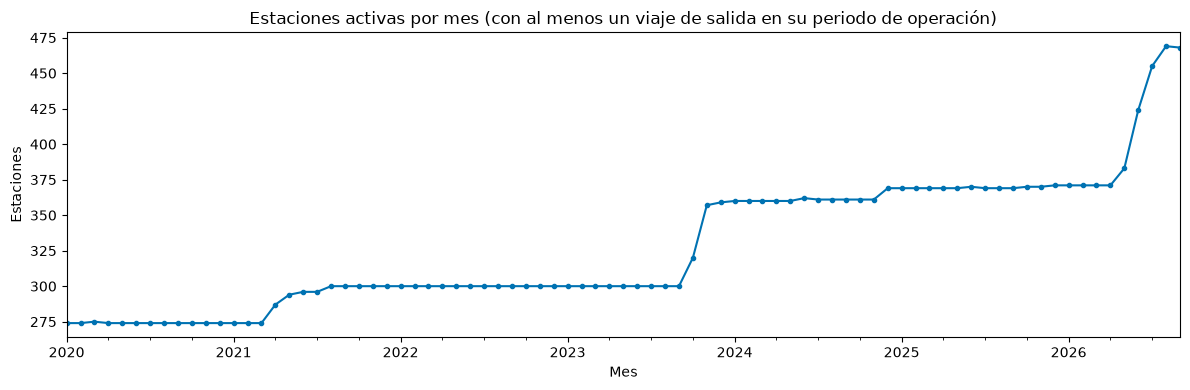

In [23]:
# Antigüedad: primer y último viaje de salida de cada estación
actividad = limpios.groupby("origen_id")["inicio_del_viaje"].agg(primer_viaje="min", ultimo_viaje="max")

print("Estaciones por año de su primer viaje:")
print(actividad["primer_viaje"].dt.year.value_counts().sort_index().to_string())
print("-" * 45)
fin_del_rango = pd.Period(MES_FIN, "M").start_time
sin_viajes_ultimo_mes = actividad[actividad["ultimo_viaje"] < fin_del_rango]
print(f"Estaciones sin viajes de salida en {MES_FIN}:", len(sin_viajes_ultimo_mes))

# Estaciones activas por mes: ya tuvieron su primer viaje y todavía no su último
meses = pd.period_range(MES_INICIO, MES_FIN, freq="M")
activas_por_mes = pd.Series([((actividad["primer_viaje"] <= mes.end_time)
                              & (actividad["ultimo_viaje"] >= mes.start_time)).sum()
                             for mes in meses],
                            index=meses,
)

fig, ax = plt.subplots(figsize=(12, 4))
activas_por_mes.plot(ax=ax, color=AZUL, marker="o", markersize=3)
ax.set_title("Estaciones activas por mes (con al menos un viaje de salida en su periodo de operación)")
ax.set_xlabel("Mes")
ax.set_ylabel("Estaciones")
plt.tight_layout()
plt.show()

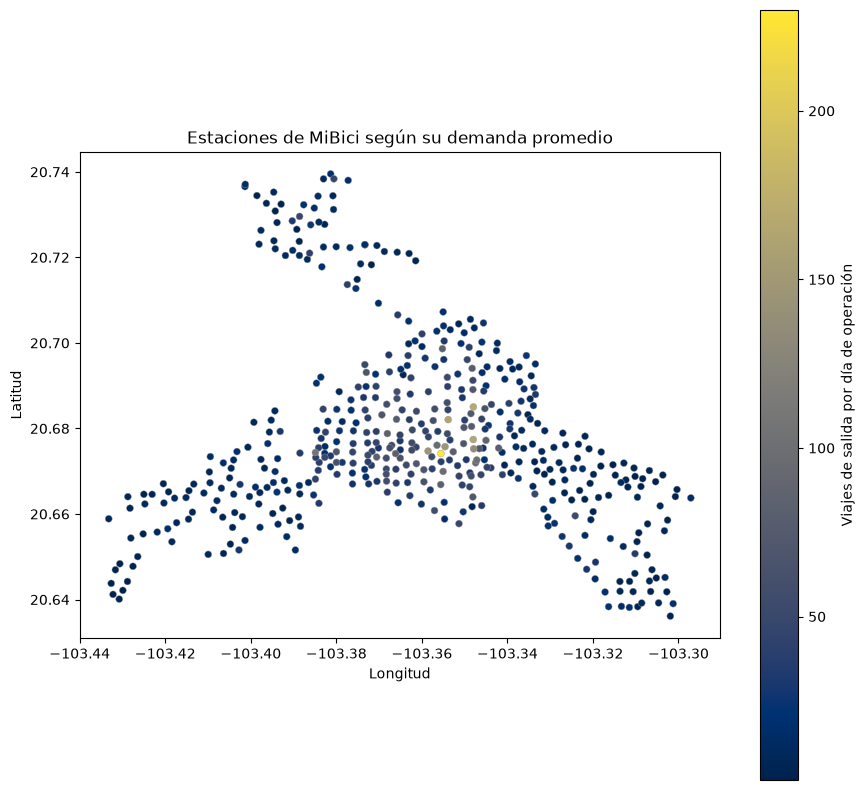

count     472.0
mean      26.96
std       26.77
min        1.51
10%         5.8
25%        9.17
50%        18.6
75%       37.08
90%       56.94
max      229.91


In [24]:
# Ubicación: viajes promedio por día de operación de cada estación
dias_operacion = (actividad["ultimo_viaje"] - actividad["primer_viaje"]).dt.days + 1
mapa = (estaciones.set_index("id")[["latitude", "longitude", "zona"]]
        .join((viajes_por_estacion / dias_operacion).rename("viajes_por_dia"), how="inner")
        .sort_values("viajes_por_dia")
)

fig, ax = plt.subplots(figsize=(9, 8))
puntos = ax.scatter(mapa["longitude"], mapa["latitude"], c=mapa["viajes_por_dia"],
                    cmap="cividis", s=25, edgecolor=GRIS, linewidth=0.3)
fig.colorbar(puntos, ax=ax, label="Viajes de salida por día de operación")
ax.set_title("Estaciones de MiBici según su demanda promedio")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

print(mapa["viajes_por_dia"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_string())

**Observaciones de los patrones espaciales:**
- **Zonas:** la nomenclatura tiene 484 estaciones en tres municipios: GDL (357, 73.76%), ZPN (110, 22.73%) y TLQ (17, 3.51%). La demanda está mucho más desbalanceada que las estaciones: GDL concentra 90.16% de los viajes de salida, ZPN 8.39% y TLQ 1.45%. Como unidad de predicción, la zona por municipio es casi igual a todo el sistema en GDL y aporta poco detalle para operar.
- **Concentración:** 472 estaciones tienen viajes de salida. El 10% con más viajes (47) concentra 37.32% de los viajes, el 20% (94) concentra 57.66% y la mitad (236) concentra 91.07%. Las 10 estaciones con más salidas están en GDL; la primera, la 51 (GDL-049), aporta 2.10%.
- **Ubicación:** en el mapa, las estaciones con más demanda se agrupan en el núcleo central de la red, y las ramas del norte, el poniente y el sureste tienen demanda baja. La demanda promedio va de 1.51 a 229.91 viajes por día de operación (mediana 18.60), así que el nivel propio de cada estación es una de las variables más importantes para la P1.
- **Antigüedad:** 275 estaciones ya operaban en 2020 (algunas pueden ser anteriores al rango). La red crece por saltos: 26 estaciones nuevas en 2021, ninguna en 2022, 59 en 2023, 11 en 2024, 3 en 2025 y **98 en 2026**, entre mayo y agosto (la red pasa de unas 370 a cerca de 470 estaciones activas). 4 estaciones no tuvieron viajes de salida en 2026-09.
- **Implicaciones para la P1:**
  - Las estaciones abiertas en 2026 tienen semanas de historia. Cualquier evaluación sobre 2026 incluye estaciones sin rezagos completos ni nivel histórico, por lo que el modelo necesita un valor de respaldo para ellas (arranque en frío).
  - El máximo de viajes de 2026-09 coincide con la red más grande del periodo; parte de ese aumento puede venir de las estaciones nuevas y no de más viajes por estación (por verificar).

### 2.6 Granularidad y horizonte de la P1

La pregunta deja abiertas la **unidad** (estación o zona) y el **periodo** (hora, día u otro). Para elegirlos se comparan cuatro granularidades del conteo de viajes iniciados:

| Granularidad | Uso operativo |
|---|---|
| Estación × hora | Decidir cuántas bicicletas tener en cada estación en cada turno |
| Estación × día | Planear la flota por estación para el día |
| Zona × hora | Planear por municipio en cada turno |
| Sistema × hora | Referencia: demanda total de la red |

Para cada una se mide:
- **% de ceros:** periodos sin viajes. Un porcentaje alto obliga a un modelo que maneje muchos ceros.
- **Media, desviación estándar y coeficiente de variación** (desviación / media): qué tan ruidosa es la serie respecto a su nivel.
- **Razón varianza / media:** en un conteo de Poisson vale 1; si es mucho mayor hay sobredispersión, lo que orienta la elección del modelo y de la métrica.

**Cómo se arma la malla.** Cada estación cuenta desde la hora de su primer viaje hasta la de su último viaje, porque antes de abrir (o después de cerrar) no hay demanda que predecir y esos ceros falsearían la comparación. Se excluyen las horas de 1:00 a 4:59, en que el servicio no opera. Dentro del periodo de operación, una hora sin viajes sí cuenta como cero.

Para el **horizonte** se mide la autocorrelación de la demanda por estación y hora: qué tanto se parece cada hora a la hora anterior, a la misma hora del día anterior y a la misma hora de la semana anterior. Si la relación con el día y la semana anteriores es fuerte, un horizonte de 24 horas se puede predecir con rezagos de 24 horas o más sin usar información del futuro.

In [25]:
# Malla de horas de servicio del rango completo (sin las horas en que el servicio no opera)
horas = pd.date_range(MES_INICIO, pd.Period(MES_FIN, "M").end_time.floor("h"), freq="h")
horas = horas[~horas.hour.isin(HORAS_SIN_SERVICIO)]
horas_por_dia = 24 - len(HORAS_SIN_SERVICIO)

# Viajes por estación y hora de inicio, sin los viajes en horas sin servicio
hora_inicio = limpios["inicio_del_viaje"].dt.floor("h")
en_servicio = ~hora_inicio.dt.hour.isin(HORAS_SIN_SERVICIO)
conteo_estacion_hora = (pd.DataFrame({"origen_id": limpios.loc[en_servicio, "origen_id"],
                                      "hora": hora_inicio[en_servicio]})
                        .groupby(["origen_id", "hora"]).size()
)

# Matriz estaciones x horas: cero donde no hubo viajes
ids_estaciones = conteo_estacion_hora.index.get_level_values("origen_id").unique().sort_values()
filas = ids_estaciones.get_indexer(conteo_estacion_hora.index.get_level_values("origen_id"))
columnas = horas.get_indexer(conteo_estacion_hora.index.get_level_values("hora"))
demanda = np.zeros((len(ids_estaciones), len(horas)), dtype="float32")
demanda[filas, columnas] = conteo_estacion_hora.to_numpy()

# Fuera del periodo de operación de cada estación no hay demanda que predecir: se marca como NaN
inicio_operacion = horas.searchsorted(actividad.loc[ids_estaciones, "primer_viaje"].dt.floor("h"))
fin_operacion = horas.searchsorted(actividad.loc[ids_estaciones, "ultimo_viaje"].dt.floor("h"), side="right")
posicion = np.arange(len(horas))
demanda[(posicion < inicio_operacion[:, None]) | (posicion >= fin_operacion[:, None])] = np.nan

print("Estaciones x horas de servicio:", demanda.shape)
print("Celdas dentro del periodo de operación:", int((~np.isnan(demanda)).sum()))
# La suma se acumula en float64: en float32 un total de 27 millones pierde precisión
print("Viajes en la malla:", int(np.nansum(demanda, dtype="float64")), "| viajes limpios en horas de servicio:", int(en_servicio.sum()))

Estaciones x horas de servicio: (472, 49300)
Celdas dentro del periodo de operación: 16103922
Viajes en la malla: 27026452 | viajes limpios en horas de servicio: 27026452


In [26]:
def resumir_conteos(matriz):
    """Resume una matriz de conteos (NaN = fuera de operación): ceros, nivel, dispersión y percentiles."""
    valores = matriz[~np.isnan(matriz)].astype("float64")
    media = valores.mean()
    varianza = valores.var()
    return {"celdas": valores.size,
            "pct_ceros": (valores == 0).mean() * 100,
            "media": media,
            "desviacion": np.sqrt(varianza),
            "coef_variacion": np.sqrt(varianza) / media,
            "varianza_media": varianza / media,
            "p50": np.percentile(valores, 50),
            "p90": np.percentile(valores, 90),
            "p99": np.percentile(valores, 99),
    }


def sumar_sin_perder_nan(matriz, eje):
    """Suma ignorando NaN, pero deja NaN donde todos los valores sumados eran NaN."""
    suma = np.nansum(matriz, axis=eje)
    suma[np.isnan(matriz).all(axis=eje)] = np.nan
    return suma


# Estación x día: las horas de servicio de cada día se suman
demanda_dia = sumar_sin_perder_nan(demanda.reshape(len(ids_estaciones), -1, horas_por_dia), eje=2)

# Zona x hora: se suman las estaciones de cada zona
zona_de_estacion = estaciones.set_index("id")["zona"].reindex(ids_estaciones).to_numpy()
zonas = sorted(set(zona_de_estacion))
demanda_zona = np.vstack([sumar_sin_perder_nan(demanda[zona_de_estacion == zona], eje=0) for zona in zonas])

# Sistema x hora: todas las estaciones
demanda_sistema = sumar_sin_perder_nan(demanda, eje=0)[None, :]

granularidades = pd.DataFrame({"Estación x hora": resumir_conteos(demanda),
                               "Estación x día": resumir_conteos(demanda_dia),
                               "Zona x hora": resumir_conteos(demanda_zona),
                               "Sistema x hora": resumir_conteos(demanda_sistema),
}).T
granularidades.astype("float64").round(2)

,celdas,pct_ceros,media,desviacion,coef_variacion,varianza_media,p50,p90,p99
Estación x hora,16103922.0,43.96,1.68,2.66,1.58,4.21,1.0,5.0,12.0
Estación x día,805408.0,0.76,33.56,33.66,1.00,33.76,24.0,71.0,170.0
Zona x hora,147894.0,3.37,182.74,286.91,1.57,450.46,37.0,642.0,1158.0
Sistema x hora,49298.0,1.49,548.23,351.06,0.64,224.80,529.0,1005.0,1535.0


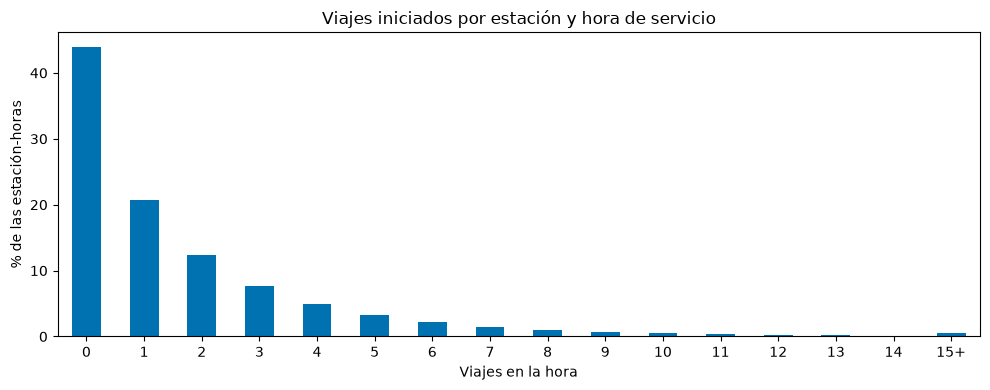

0      43.96
1      20.74
2      12.30
3       7.66
4       4.93
5       3.23
6       2.13
7       1.44
8       0.98
9       0.68
10      0.48
11      0.35
12      0.26
13      0.19
14      0.14
15+     0.54


In [27]:
# Distribución de los viajes por estación y hora (proporción de celdas con 0, 1, 2, ... viajes)
valores_estacion_hora = demanda[~np.isnan(demanda)]
proporcion = (pd.Series(np.minimum(valores_estacion_hora, 15)).value_counts(normalize=True)
              .sort_index().mul(100)
)
proporcion.index = [str(int(v)) if v < 15 else "15+" for v in proporcion.index]

fig, ax = plt.subplots(figsize=(10, 4))
proporcion.plot.bar(ax=ax, color=AZUL)
ax.set_title("Viajes iniciados por estación y hora de servicio")
ax.set_xlabel("Viajes en la hora")
ax.set_ylabel("% de las estación-horas")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(proporcion.round(2).to_string())

In [28]:
def autocorrelacion_por_fila(matriz, rezago):
    """Correlación de cada fila con ella misma desplazada `rezago` columnas, usando solo pares sin NaN."""
    actual, anterior = matriz[:, rezago:], matriz[:, :-rezago]
    validos = ~np.isnan(actual) & ~np.isnan(anterior)
    actual = np.where(validos, actual, np.nan)
    anterior = np.where(validos, anterior, np.nan)
    actual = actual - np.nanmean(actual, axis=1, keepdims=True)
    anterior = anterior - np.nanmean(anterior, axis=1, keepdims=True)
    return (np.nansum(actual * anterior, axis=1)
            / np.sqrt(np.nansum(actual**2, axis=1) * np.nansum(anterior**2, axis=1)))


# Rezagos medidos en horas de servicio: 20 posiciones = misma hora del día anterior
rezagos = {"1 hora antes": 1,
           "Misma hora, día anterior": horas_por_dia,
           "Misma hora, semana anterior": 7 * horas_por_dia,
}
autocorrelaciones = pd.DataFrame({nombre: autocorrelacion_por_fila(demanda, rezago)
                                  for nombre, rezago in rezagos.items()},
                                 index=ids_estaciones,
)
print("Autocorrelación de la demanda por estación y hora (distribución entre estaciones):")
autocorrelaciones.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T.round(2)

Autocorrelación de la demanda por estación y hora (distribución entre estaciones):


,count,mean,std,min,10%,25%,50%,75%,90%,max
1 hora antes,472.0,0.27,0.15,-0.04,0.08,0.14,0.25,0.38,0.47,0.76
"Misma hora, día anterior",472.0,0.33,0.13,-0.01,0.16,0.23,0.33,0.42,0.49,0.72
"Misma hora, semana anterior",472.0,0.39,0.15,0.03,0.20,0.27,0.40,0.50,0.57,0.78


**Observaciones de granularidad y horizonte:**
- **Malla:** 472 estaciones por 49300 horas de servicio; 16103922 estación-horas caen dentro del periodo de operación de cada estación. La suma de la malla debe coincidir con los viajes limpios en horas de servicio (27026452); la primera versión de la validación sumaba en float32 y mostraba 52 viajes de diferencia por redondeo, no por viajes perdidos.
- **Estación x hora:** 43.96% de ceros, media de 1.68 viajes y razón varianza/media de 4.21. Es un conteo con muchos ceros y sobredispersión (más variable que un Poisson). El 77.00% de las estación-horas tiene 0, 1 o 2 viajes, y solo el 1% supera 12 (p99).
- **Estación x día:** casi no hay ceros (0.76%) y la media sube a 33.56, pero el total diario esconde los picos de las 8:00 y las 18:00, que es cuando la flota se queda corta.
- **Zona x hora:** el desbalance entre municipios se refleja en una razón varianza/media de 450.46: mezcla una zona que es casi todo el sistema con dos zonas pequeñas.
- **Sistema x hora:** media de 548.23 viajes por hora y coeficiente de variación de 0.64; es la serie más estable, pero no responde a la pregunta por estación.
- **Horizonte:** en la mediana de las estaciones, la correlación con la hora anterior es 0.25, con la misma hora del día anterior 0.33 y con la misma hora de la semana anterior 0.40. Los rezagos de un día y de una semana tienen más señal que el de una hora, así que predecir con un día de anticipación pierde poca información. Las correlaciones son moderadas: cada estación-hora es ruidosa, por lo que promedios de varias semanas a la misma hora podrían aportar más que un solo rezago (hipótesis para el modelado).

### 2.7 Conclusiones: formulación de la P1

| Elemento | Decisión | Evidencia |
|---|---|---|
| **Qué se predice** | Número de viajes que **inician** en cada estación en cada hora de servicio | La P1 pregunta por viajes iniciados; se cuentan por `origen_id` y la hora de `inicio_del_viaje` de los viajes limpios |
| **Granularidad** | **Estación x hora**, de 5:00 a 0:59 (20 horas por día) | Conserva los picos de las 8:00 y las 18:00 que el total diario esconde (2.4, 2.6); la zona por municipio es demasiado gruesa (90.16% de los viajes en GDL); las horas de 1:00 a 4:59 se excluyen porque el servicio no opera |
| **Zona** | Se reporta sumando las predicciones de sus estaciones | Responde a "estación o zona" sin un segundo modelo |
| **Horizonte** | **El día siguiente:** al cierre del día D se predicen las 20 horas de servicio del día D+1 | La pausa de 1:00 a 4:59 es la ventana natural para preparar la flota; los rezagos de un día y una semana tienen más señal que el de una hora (2.6) |
| **Información permitida** | Solo datos hasta el cierre del día anterior: rezagos de 24 horas o más | Evita data leakage: ninguna variable usa viajes del día que se predice |
| **Usuario y decisión** | Operador del sistema: cuántas bicicletas dejar en cada estación para cada franja del día siguiente | Pregunta de negocio de la P1 |

**Propuesta de variables** (se implementan en `features.py`):
- **Calendario:** hora, día de la semana, fin de semana, día festivo y mes (2.4).
- **Rezagos:** misma hora del día anterior y de la semana anterior, y promedio de las últimas semanas a la misma hora (2.6).
- **Estación:** nivel histórico calculado solo con entrenamiento, días desde su primer viaje y zona (2.5).

**Métrica:** MAE en viajes por estación-hora como métrica principal, porque se interpreta directamente en bicicletas; RMSE como complemento, porque castiga más los errores en las horas pico. No se usa MAPE: el 43.96% de las estación-horas tiene cero viajes y el porcentaje no está definido.

**Partición:** se adopta la partición temporal del equipo (entrenamiento hasta 2024-09, validación de 2024-10 a 2025-09 y prueba de 2025-10 a 2026-09, con 24 horas de brecha en cada frontera). La brecha coincide con el horizonte de la P1 y los bloques de 12 meses cubren todas las temporadas del año. Los rezagos sí pueden tomar valores del conjunto anterior, porque es información disponible al momento de predecir.

**Riesgos para el modelado:**
- **Arranque en frío:** 98 estaciones abrieron en 2026, dentro del periodo de prueba, con poca o ninguna historia.
- **Cambio de nivel:** el entrenamiento incluye la pandemia de 2020 y el crecimiento de 2022; un nivel histórico calculado con todo el entrenamiento puede quedar por debajo de la demanda reciente.
- **Ruido por estación-hora:** autocorrelaciones moderadas (mediana de 0.25 a 0.40), por lo que conviene comparar cualquier modelo contra un baseline estacional simple.